In [ ]:
import json

notebook_path = r"C:\Users\nadip\Downloads\student-performance-multiple-linear-regression.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("Notebook opened successfully!\n")

for i, cell in enumerate(notebook["cells"]):
    print(f"\n--- Cell {i+1} ({cell['cell_type']}) ---")
    print("".join(cell["source"])[:1500])


In [ ]:
from pathlib import Path

downloads = Path(r"C:\Users\nadip\Downloads")

for file in downloads.rglob("Student_Performance.csv"):
    print(file)


In [ ]:
print("Python is working!")

In [ ]:
from pathlib import Path

downloads = Path(r"C:\Users\nadip\Downloads")

for file in downloads.rglob("Student_Performance.csv"):
    print(file)

In [ ]:
from pathlib import Path

downloads = Path(r"C:\Users\nadip\Downloads")

for item in downloads.iterdir():
    print(item.name)

Dataset:
   Study_Hours  Attendance  Assignment_Marks  Marks
0            1          50                10     35
1            2          55                12     40
2            3          60                15     45
3            4          65                16     50
4            5          70                18     55
5            6          75                20     60
6            7          80                22     65
7            8          85                24     70
8            9          90                26     80
9           10          95                28     90

--- Simple Linear Regression ---
Intercept: 26.98275862068966
Coefficient: 5.775862068965517
R2 Score: 0.9959776307966706
RMSE: 1.2684430146174304

--- Multiple Linear Regression ---
Intercept: -15.294943820224617
Coefficients: [0.15449438 0.77247191 0.8988764 ]
R2 Score: 0.9950517216891807
RMSE: 1.406879996420352

Predicted marks using Simple Regression: 61.63793103448276
Predicted marks using Multiple Regression:

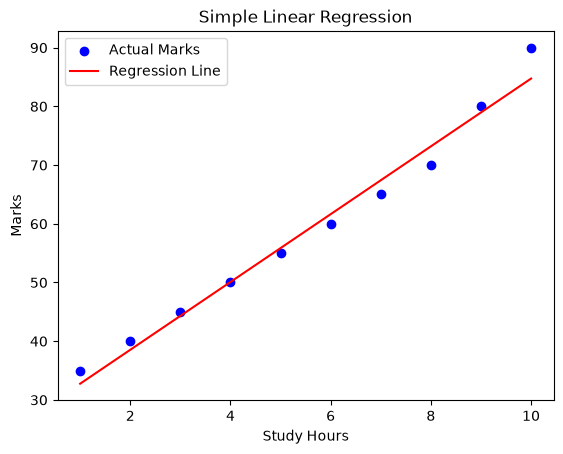

In [3]:

# Simple and Multiple Linear Regression

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Step 1: Create a sample dataset
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Attendance": [50, 55, 60, 65, 70, 75, 80, 85, 90, 95],
    "Assignment_Marks": [10, 12, 15, 16, 18, 20, 22, 24, 26, 28],
    "Marks": [35, 40, 45, 50, 55, 60, 65, 70, 80, 90]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Step 2: Select input and output variables
X_simple = df[["Study_Hours"]]

X_multiple = df[
    ["Study_Hours", "Attendance", "Assignment_Marks"]
]

y = df["Marks"]

# Step 3: Split the data
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

X_train_m, X_test_m, _, _ = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

# Step 4: Simple Linear Regression
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train)

simple_predictions = simple_model.predict(X_test_s)

print("\n--- Simple Linear Regression ---")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_score(y_test, simple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, simple_predictions)
))

# Step 5: Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train)

multiple_predictions = multiple_model.predict(X_test_m)

print("\n--- Multiple Linear Regression ---")
print("Intercept:", multiple_model.intercept_)
print("Coefficients:", multiple_model.coef_)
print("R2 Score:", r2_score(y_test, multiple_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
))

# Step 6: Predict marks for a new student
new_student_simple = pd.DataFrame({
    "Study_Hours": [6]
})

new_student_multiple = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [80],
    "Assignment_Marks": [22]
})

print("\nPredicted marks using Simple Regression:",
      simple_model.predict(new_student_simple)[0])

print("Predicted marks using Multiple Regression:",
      multiple_model.predict(new_student_multiple)[0])

# Step 7: Plot Simple Linear Regression
plt.scatter(
    df["Study_Hours"], df["Marks"],
    color="blue", label="Actual Marks"
)

plt.plot(
    df["Study_Hours"],
    simple_model.predict(X_simple),
    color="red", label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()


In [4]:
# Display first five rows
print(df.head())

# Display number of rows and columns
print("\nDataset shape:")
print(df.shape)

# Display column names
print("\nColumn names:")
print(df.columns)

# Display data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical summary:")
print(df.describe())


   Study_Hours  Attendance  Assignment_Marks  Marks
0            1          50                10     35
1            2          55                12     40
2            3          60                15     45
3            4          65                16     50
4            5          70                18     55

Dataset shape:
(10, 4)

Column names:
Index(['Study_Hours', 'Attendance', 'Assignment_Marks', 'Marks'], dtype='str')

Data types:
Study_Hours         int64
Attendance          int64
Assignment_Marks    int64
Marks               int64
dtype: object

Missing values:
Study_Hours         0
Attendance          0
Assignment_Marks    0
Marks               0
dtype: int64

Statistical summary:
       Study_Hours  Attendance  Assignment_Marks      Marks
count     10.00000   10.000000         10.000000  10.000000
mean       5.50000   72.500000         19.100000  59.000000
std        3.02765   15.138252          5.971227  17.606817
min        1.00000   50.000000         10.000000  35.000000

In [5]:
# Outlier detection using IQR

Q1 = df["Marks"].quantile(0.25)
Q3 = df["Marks"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Marks"] < lower_limit) |
    (df["Marks"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Outliers:")
print(outliers)


Q1: 46.25
Q3: 68.75
IQR: 22.5
Lower limit: 12.5
Upper limit: 102.5
Outliers:
Empty DataFrame
Columns: [Study_Hours, Attendance, Assignment_Marks, Marks]
Index: []


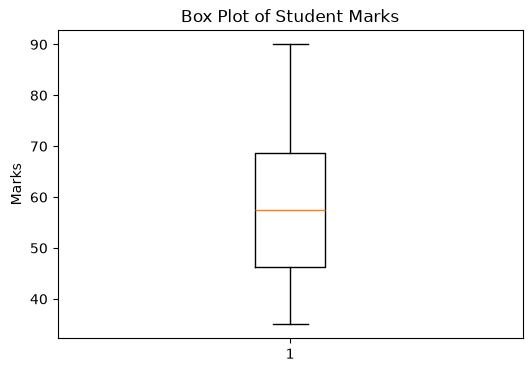

In [6]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["Marks"])
plt.title("Box Plot of Student Marks")
plt.ylabel("Marks")
plt.show()


Correlation Matrix:
                  Study_Hours  Attendance  Assignment_Marks     Marks
Study_Hours          1.000000    1.000000          0.998715  0.990067
Attendance           1.000000    1.000000          0.998715  0.990067
Assignment_Marks     0.998715    0.998715          1.000000  0.989211
Marks                0.990067    0.990067          0.989211  1.000000


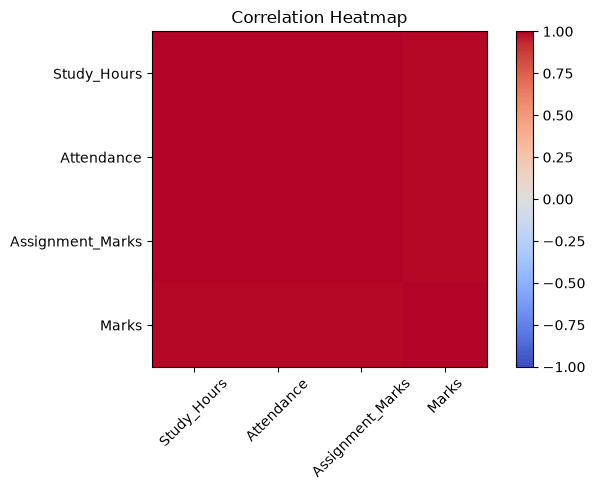

In [7]:
correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
print(correlation)

plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)),
           correlation.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [8]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    precision_score, recall_score, f1_score
)

# Create dataset
log_df = pd.DataFrame({
    "Hours_Studied": [
        1, 2, 3, 4, 5, 6, 7, 8, 2, 3,
        5, 6, 7, 8, 9, 1, 4, 6, 8, 9
    ],
    "Pass": [
        0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
        1, 1, 1, 1, 1, 0, 0, 1, 1, 1
    ]
})

X = log_df[["Hours_Studied"]]
y = log_df["Pass"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("Predicted values:")
print(y_pred)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))
print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))


Actual values:
[0 1 0 1 1 1]
Predicted values:
[0 1 0 1 1 1]
Accuracy: 1.0
Confusion Matrix:
[[2 0]
 [0 4]]
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
